# Which GPU work did PyTorch launch?

`capture` profiles one warmed-up training step and returns `prof.events()`.
`rows` holds every event once, with `launcher_id` pointing at the event that
launched it (a CPU op's `cpu_parent`, or a kernel's CUDA launch call), so
`aten::mm -> cudaLaunchKernel -> kernel` is a chain of `launcher_id` links.

Module hooks record `forward::<module_fqn>` scopes, and autograd node hooks restore
the same path as `backward::<module_fqn>` during backward. A kernel belongs to its
nearest module scope; with none it is `<unattributed>`. `aggregate_kernels` does the
attribution and raises if a kernel is owned by a module but never reaches the root scope.

1. Setup and capture
2. Every kernel with its module
3. Time per module
4. Timeline
5. FLOPs check
6. Appendix: what each id is, and one kernel's launch chain

In [13]:
import pickle

import pandas as pd
import torch
from profile_events import (
    aggregate_kernels,
    allocations_by_label,
    display_timeline,
    events_to_rows,
    link_events,
    memory_clock_offsets,
    memory_over_time,
    module_scopes,
    transformer_matmul_comparison,
)

from models.transformer import Transformer

model = Transformer(
    vocab_size=10000,
    d_model=512,
    d_ff=1344,
    sequence_length=250,
    num_layers=4,
    num_heads=16,
    rope_theta=10000,
    device="cuda",  # has to agree with app.GPU; the preflight checks it
    dtype="torch.float32",  # strings parsed in the worker container
)
tokens = torch.randint(
    0, 100, (8, 250),
    generator=torch.Generator().manual_seed(0),
)

### What `capture` does

`capture` runs on a GPU worker and profiles one training step.

1. Record memory use, build the model and make random tokens, then record memory use again.
2. Run a few warmup steps, unprofiled.
3. Run one step under the profiler, with the CUDA allocator recording its history. Each phase of the step is wrapped in `record_function`, so it shows up by name: `train::zero_grad`, `train::forward`, `train::loss`, `train::backward`, `train::optimizer_step`.
4. Return the profiler's events, the allocator's `memory_snapshot`, each device's `total_memory` (VRAM, from the device properties), the `memory_checkpoints` from before the model, after it, after warmup and after the step, and the `size_estimation` (parameter count and bytes, for the model and the optimizer state).

**`record_function(name)`** adds a `user_annotation` event with that name. It is a label we add, not an operation PyTorch ran. Anything that starts and ends inside its time span becomes its child, so parent and child are decided by timestamps.

**`module_scopes(model)`** does the same per module: `forward::<module>` around each module's forward call, and `backward::<module>` around the backward work it owns. Later, a kernel is assigned to the module whose scope contains its launch.

A typical start of the events, in order, with start and end times in microseconds (illustrative values; the ids are from a real capture). `device_type` says where an event executed, CPU or GPU. Each indented row is a child of the row above it that is one level less indented. Annotations are ours, the rest is PyTorch:

```
                                          device_type     activity_type                               correlation_id        linked_correlation_id  start    end
train::zero_grad                          DeviceType.CPU  user_annotation                      1 (frontend, PyTorch)                            0      0     40
  Optimizer.zero_grad#AdamW.zero_grad     DeviceType.CPU  user_annotation (PyTorch's own)      2 (frontend, PyTorch)                            0      5     35
train::forward                            DeviceType.CPU  user_annotation                      3 (frontend, PyTorch)                            0     40   4200
  forward::model                          DeviceType.CPU  user_annotation                      4 (frontend, PyTorch)                            0     45   4190
    forward::model.embedding              DeviceType.CPU  user_annotation                      5 (frontend, PyTorch)                            0     50    300
      aten::index                         DeviceType.CPU  cpu_op                               6 (frontend, PyTorch)                            0     60    290
        cudaLaunchKernel                  DeviceType.CPU  cuda_runtime                           11 (backend, CUPTI)        6 (frontend, PyTorch)    100    120
          vectorized_gather_kernel        DeviceType.CUDA kernel (on the GPU)                    11 (backend, CUPTI)        6 (frontend, PyTorch)    130    142
```

**Linking.** Parent and child among CPU events come from the timestamps, as above. A GPU event has no CPU parent in the trace, so `link_events` finds its launcher with correlation ids.

**CUDA** is NVIDIA's platform for running programs on its GPUs. It has a CPU side and a GPU side:

- On the CPU, the CUDA runtime library (`cuda_runtime` events, e.g. `cudaLaunchKernel`, `cudaMemcpyAsync`) and the lower-level driver it calls into (`cuda_driver`). These are ordinary CPU function calls that queue work for the GPU and return immediately.
- On the GPU, the work that was queued: `kernel`, `gpu_memcpy`, `gpu_memset`.

The `correlation_id` column holds ids from two separate namespaces, and the same number can appear in both. The boundary is who recorded the event, not CPU versus GPU:

- **Frontend:** events PyTorch's own profiler records for the operations your Python code calls: `cpu_op` and `user_annotation`. PyTorch numbers them with its own counter (1 to 6 above).
- **Backend:** every event of the CUDA layer, recorded by CUPTI, NVIDIA's profiling library (the CUDA Profiling Tools Interface). That is both the CPU-side CUDA calls (`cuda_runtime`, `cuda_driver`) and the GPU work they launch (`kernel`, `gpu_memcpy`, `gpu_memset`). CUPTI numbers them with its own counter (11 above), and a kernel gets the same id as the call that launched it.

So `device_type` is not the namespace boundary. `cudaLaunchKernel` has `DeviceType.CPU` because it executes on the CPU, yet its `correlation_id` is a backend id. `DeviceType.CUDA` marks only the GPU-side events, so it is not a name for the whole backend namespace. The namespace follows `activity_type`.

`linked_correlation_id` crosses between them. On a launch call or GPU event it holds the frontend `correlation_id` of the op that issued the launch (6, `aten::index`).

`link_events` keeps one lookup per namespace, so an id is only ever compared with ids of its own kind:

1. A kernel's backend `correlation_id` is looked up among the launch calls, so it is matched to the `cuda_runtime` call that launched it (11).
2. The launch call's `linked_correlation_id` is looked up among the frontend ids, so the call is matched to the op that issued it (6).

Each match sets `launcher_id` to the matched event's row. Following `launcher_id` from the kernel gives `kernel -> cudaLaunchKernel -> aten::index -> forward::model.embedding -> ...`, which is how a kernel finds its module scope. If a match is missing or ambiguous, `launcher_id` stays empty and the kernel is unattributed. See "What each id is" in the appendix.

In [14]:
import modal

import main

app = modal.App("profile-events")
# The worker image, so its torch is the uv.lock version that unpickles the events locally.
# The container imports profile_events for module_scopes.
image = main.worker_image.add_local_python_source("profile_events")


@app.function(image=image, gpu="L4", timeout=300)
def capture(declaration, tokens, warmup_steps=5) -> tuple:
    """Warm up full training steps, then profile one step on the same model.

    Returns (profiler events, CUDA allocator snapshot, total memory in bytes per device,
    memory checkpoints, size estimation). size_estimation is {"model": ..., "optimizer": ...},
    each with the number of parameters (elements) and their bytes; the optimizer counts its state
    tensors after warmup, when they exist. The checkpoints hold allocated, reserved and device_used bytes before the
    model is built, after it is built, after warmup and after the profiled step; device_used is
    total minus free VRAM from the driver, so it includes the CUDA context.

    Warmup includes forward, loss, backward and optimizer.step so CUDA libraries
    and optimizer state are initialized. Warmup events are not recorded.
    """
    import torch
    from torch import nn
    from torch.profiler import ProfilerActivity, profile, record_function

    def size_of(tensors):
        tensors = list(tensors)
        return {"parameters": sum(t.numel() for t in tensors),
                "bytes": sum(t.numel() * t.element_size() for t in tensors)}

    def memory_use():
        free, total = torch.cuda.mem_get_info()
        return {"allocated": torch.cuda.memory_allocated(), "reserved": torch.cuda.memory_reserved(),
                "device_used": total - free}

    checkpoints = {"before_model": memory_use()}
    torch.manual_seed(0)
    model = declaration.build()
    tokens = tokens.to("cuda")
    checkpoints["after_model"] = memory_use()
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    # Next-token prediction: each position predicts the following input token.
    targets = tokens[:, 1:].reshape(-1)

    def train_step():
        with record_function("train::zero_grad"):
            optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            with record_function("train::forward"):
                logits = model(tokens)
            with record_function("train::loss"):
                loss = nn.functional.cross_entropy(
                    logits[:, :-1, :].reshape(-1, logits.shape[-1]), targets
                )
        with record_function("train::backward"):
            loss.backward()
        with record_function("train::optimizer_step"):
            optimizer.step()

    # Complete warmup before profiling: no queued warmup work enters the trace.
    for _ in range(warmup_steps):
        train_step()
    torch.cuda.synchronize()
    checkpoints["after_warmup"] = memory_use()
    size_estimation = {
        "model": size_of(model.parameters()),
        "optimizer": size_of(t for state in optimizer.state.values() for t in state.values() if torch.is_tensor(t)),
    }

    torch.cuda.memory._record_memory_history(max_entries=100_000)
    with profile(
        activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
        record_shapes=False,
        with_stack=False,
        with_flops=True,
        profile_memory=False
    ) as prof, module_scopes(model):
        train_step()
        # Kernels run asynchronously. Wait for them inside the profiler so every launched
        # activity has finished, and been recorded, before collection stops.
        torch.cuda.synchronize()
    # A plain dict of segments, blocks and allocator trace entries: it pickles without a file.
    memory_snapshot = torch.cuda.memory._snapshot()
    torch.cuda.memory._record_memory_history(enabled=None)
    # The FunctionEvents themselves: they pickle with their cpu_parent/cpu_children references.
    checkpoints["after_step"] = memory_use()
    total_memory = [torch.cuda.get_device_properties(i).total_memory for i in range(torch.cuda.device_count())]
    return list(prof.events()), memory_snapshot, total_memory, checkpoints, size_estimation

In [15]:
# enable_output streams image builds and the container's logs into this cell.
with app.run():
    function_events, memory_snapshot, total_memory, memory_checkpoints, size_estimation = capture.remote(model, tokens, warmup_steps=5)
print(f"{len(function_events)} events")
rows = events_to_rows(function_events)

10454 events


In [16]:
# MiB at each checkpoint, and the change from the previous one. device_used includes the CUDA context.
for name, size in size_estimation.items():
    print(f"{name}: {size['parameters']:,} parameters, {size['bytes'] / 2**20:.1f} MiB")
persistent_memory = 2 * size_estimation["model"]["bytes"] + size_estimation["optimizer"]["bytes"]  # weights, gradients, optimizer state
checkpoints = pd.DataFrame(memory_checkpoints).T.div(2**20)
pd.concat({"MiB": checkpoints, "change": checkpoints.diff()}, axis=1)

model: 22,696,448 parameters, 86.6 MiB
optimizer: 45,392,935 parameters, 173.2 MiB


MiB                           change                     
               allocated reserved device_used   allocated reserved device_used
before_model    0.000000      0.0    195.4375         NaN      NaN         NaN
after_model    87.898438    120.0    347.4375   87.898438    120.0       152.0
after_warmup  368.195312   1026.0   1277.4375  280.296875    906.0       930.0
after_step    368.195312   1026.0   1289.4375    0.000000      0.0        12.0

**Two kinds of allocated memory.**

- **Persistent:** lives for the whole run. For a transformer trained with Adam in fp32 this is the weights, their gradients, and Adam's two moment buffers (`exp_avg`, `exp_avg_sq`), so about 4 times the size of the model. `after_warmup` allocated should be close to 4 times `after_model` allocated.
- **Activation:** transient. The forward pass saves intermediate tensors for backward, so allocated memory climbs through forward, peaks around the start of backward, and falls as backward frees them. In the memory plot it is the bump above the persistent level.

Reserved memory does not fall back with it: the caching allocator keeps the freed blocks, so reserved stays at the high-water mark.

In [17]:
# Bytes allocated while each record_function scope was the innermost open one.
allocations = allocations_by_label(memory_snapshot)
allocations

,addr,size,start_us,end_us,label
0,47984913317888,4096000,1791849613819707,1.791850e+15,forward::model.embedding
1,47984458040320,2000,1791849613822191,1.791850e+15,forward::model.tblocks.0
2,47985018798080,4096000,1791849613822485,1.791850e+15,forward::model.tblocks.0.norm1
3,47984458151936,8000,1791849613822628,1.791850e+15,forward::model.tblocks.0.norm1
4,47984458160128,8000,1791849613822819,1.791850e+15,forward::model.tblocks.0.norm1
...,...,...,...,...,...
810,47985351196672,1048576,1791849614054408,1.791850e+15,Optimizer.step#AdamW.step
811,47984458162176,2048,1791849614054413,1.791850e+15,Optimizer.step#AdamW.step
812,47985292738560,2752512,1791849614054426,1.791850e+15,Optimizer.step#AdamW.step
813,47984871505920,2752512,1791849614054431,1.791850e+15,Optimizer.step#AdamW.step


## Every kernel and its module

In [18]:
# Raises if a module-owned kernel never reaches the root scope.
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
print(f"{len(kernels)} kernels, {len(unattributed_kernels)} unattributed")
assert len(unattributed_kernels) < len(kernels), "No kernel has a module: check module_scopes and root"
# Unattributed kernels show module_fqn "<unattributed>".
kernel_table = kernels[["name", "phase", "module_fqn", "owner_fqn", "duration_us", "gpu_start_us", "device_memory_usage", "cpu_memory_usage"]].sort_values('device_memory_usage')
display(kernel_table)

827 kernels, 97 unattributed


,name,phase,module_fqn,owner_fqn,duration_us,gpu_start_us,device_memory_usage,cpu_memory_usage
index,,,,,,,,
11,"void at::native::vectorized_gather_kernel<16, ...",forward,model.embedding,model.embedding,6.240,6632.054,0,0
7103,ampere_bf16_s1688gemm_bf16_128x128_ldg8_f2f_st...,backward,model.tblocks.1,model.tblocks.1.attention,22.432,170809.062,0,0
7177,void at::native::unrolled_elementwise_kernel<a...,backward,model.tblocks.1,model.tblocks.1.attention,3.168,173113.935,0,0
7216,"void at::native::elementwise_kernel<128, 4, at...",backward,model.tblocks.1,model.tblocks.1.attention,11.327,174115.590,0,0
7230,void cutlass::Kernel2<cutlass_80_wmma_tensorop...,backward,model.tblocks.1,model.tblocks.1.attention,74.207,174567.297,0,0
...,...,...,...,...,...,...,...,...
2278,void at::native::vectorized_elementwise_kernel...,forward,model.tblocks.3,model.tblocks.3.norm2,1.472,52780.752,0,0
2290,"void at::native::elementwise_kernel<128, 4, at...",forward,model.tblocks.3,model.tblocks.3.norm2,6.688,52851.279,0,0
2299,void at::native::vectorized_elementwise_kernel...,forward,model.tblocks.3,model.tblocks.3.ffn,12.928,53203.212,0,0


## Time per module

In [19]:
# gpu_time_us sums kernel durations; gpu_span_us also includes gaps between launches.
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])

kernel_count  gpu_time_us  gpu_span_us  \
phase          module_fqn                                                
forward        model.embedding             1        6.240        6.240   
               model.linear                2      393.692      465.531   
               model.norm                  8       32.736      684.634   
               model.tblocks.0            70     1173.621    11709.581   
               model.tblocks.1            70     1148.599    11925.931   
               model.tblocks.2            70     1159.573    11618.222   
               model.tblocks.3            70     1150.160    11888.363   
loss           <unattributed>              4     1154.741     1156.821   
backward       <unattributed>             85     2704.068   178451.043   
               model.embedding             7       58.848      572.794   
               model.linear                3      674.105      677.209   
               model.norm                 17      134.494     2623.109   
               model.tblocks.0           103     2212.042    34965.928   
               model.tblocks.1           103     2213.097    48142.503   
               model.tblocks.2           103     2196.592    45354.498   
               model.tblocks.3           103     2206.154    40746.543   
optimizer_step <unattributed>              8     7842.802     7847.795   

                                estimated_flops  
phase          module_fqn                        
forward        model.embedding     0.000000e+00  
               model.linear        2.048000e+10  
               model.norm          1.026000e+06  
               model.tblocks.0     1.348637e+10  
               model.tblocks.1     1.348637e+10  
               model.tblocks.2     1.348637e+10  
               model.tblocks.3     1.348637e+10  
loss           <unattributed>      0.000000e+00  
backward       <unattributed>      8.192000e+06  
               model.embedding     2.000000e+03  
               model.linear        4.096000e+10  
               model.norm          5.124000e+06  
               model.tblocks.0     2.698478e+10  
               model.tblocks.1     2.698478e+10  
               model.tblocks.2     2.698478e+10  
               model.tblocks.3     2.698478e+10  
optimizer_step <unattributed>      0.000000e+00

## Timeline

In [20]:
# The allocator and the profiler have separate clocks. Each record_function scope starts at one
# moment in both, so offset_us is constant if their clocks tick alike.
offsets = memory_clock_offsets(rows, memory_snapshot)
print(f"{len(offsets)} matched scopes, offset spread {offsets['offset_us'].max() - offsets['offset_us'].min():.1f} us")
offsets["offset_us"].describe()

2381 matched scopes, offset spread 369.2 us


count    2.381000e+03
mean     1.791850e+15
std      2.631491e+01
min      1.791850e+15
25%      1.791850e+15
50%      1.791850e+15
75%      1.791850e+15
max      1.791850e+15
Name: offset_us, dtype: float64

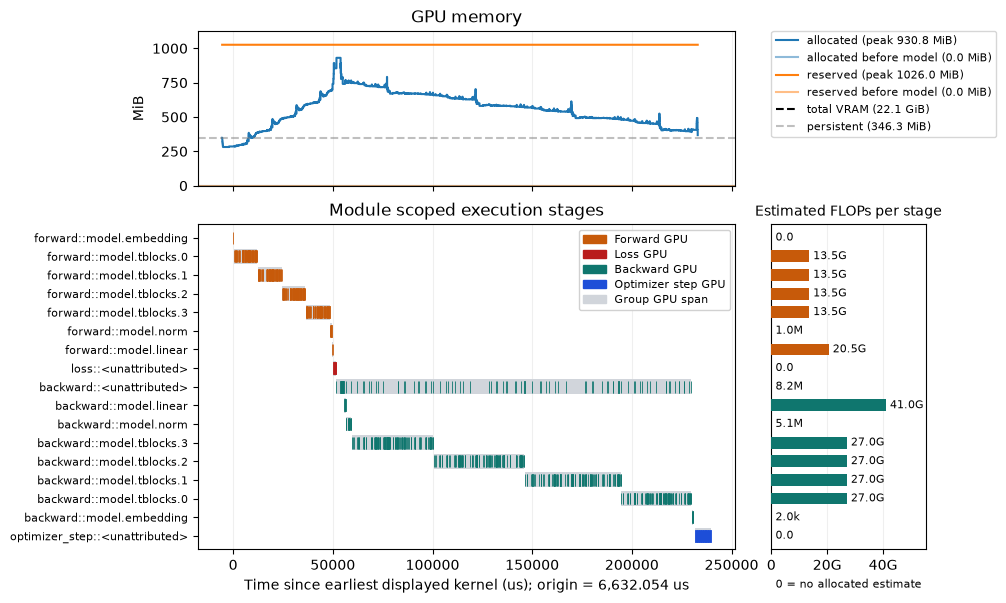

In [21]:
usage = memory_over_time(memory_snapshot)[0]
usage = usage.set_axis(usage.index - offsets["offset_us"].median())
display_timeline(groups, kernels, figsize=(10, 6), show_flops=True, memory=usage, total_memory=total_memory[0],
                 memory_baseline=memory_checkpoints["before_model"],
                 persistent_memory=persistent_memory)

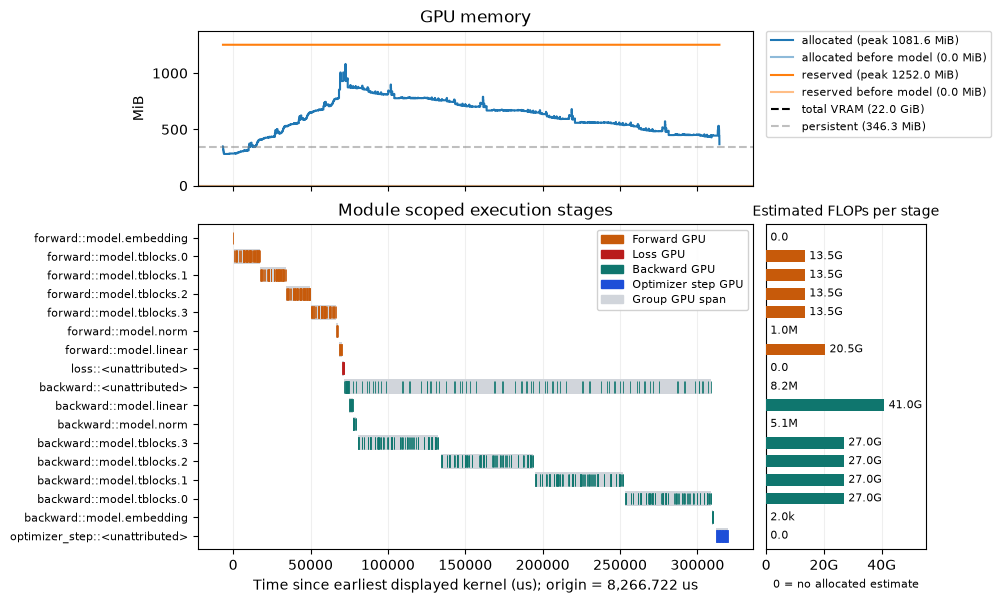

In [10]:
usage = memory_over_time(memory_snapshot)[0]
usage = usage.set_axis(usage.index - offsets["offset_us"].median())
display_timeline(groups, kernels, figsize=(10, 6), show_flops=True, memory=usage, total_memory=total_memory[0],
                 memory_baseline=memory_checkpoints["before_model"],
                 persistent_memory=persistent_memory)

## FLOPs check

In [11]:
from dataclasses import replace

batch, sequence = tokens.shape
parameter_count = sum(parameter.numel() for parameter in replace(model, device="cpu").build().parameters())
print(f"Parameters: {parameter_count:,}; tokens: {batch * sequence:,}")
print(f"6 × all parameters × tokens: {6 * parameter_count * batch * sequence / 1e6:,.3f} MFLOPs")
print("Comparison below in MFLOPs; matrix estimates exclude normalization, activations, loss and optimizer work.")
phase_comparison, stage_comparison = transformer_matmul_comparison(model, tokens, rows)
display(phase_comparison.div(1e6).round(6))
display(stage_comparison.div(1e6).round(6))
# 0 reported non-matrix FLOPs is not proof of zero work: many operations have
# no estimate. Backward = 2*forward applies to this unfrozen dense model's
# matmuls; freezing weights, detaching tensors or changing the model alters it.

Parameters: 22,696,448; tokens: 2,000
6 × all parameters × tokens: 272,357.376 MFLOPs
Comparison below in MFLOPs; matrix estimates exclude normalization, activations, loss and optimizer work.


,analytical_matmul_flops,profiler_matmul_flops,profiler_total_flops,profiler_other_flops,matmul_difference
phase,,,,,
forward,74383.36,74383.36,74426.514,43.154,0.0
backward,148766.72,148766.72,148912.422,145.702,0.0
forward + backward,223150.08,223150.08,223338.936,188.856,0.0


analytical_matmul_flops  \
phase    module_fqn                                           
backward model.linear                             40960.000   
         model.tblocks.0.attention                10436.608   
         model.tblocks.0.ffn                      16515.072   
         model.tblocks.1.attention                10436.608   
         model.tblocks.1.ffn                      16515.072   
         model.tblocks.2.attention                10436.608   
         model.tblocks.2.ffn                      16515.072   
         model.tblocks.3.attention                10436.608   
         model.tblocks.3.ffn                      16515.072   
forward  model.linear                             20480.000   
         model.tblocks.0.attention                 5218.304   
         model.tblocks.0.ffn                       8257.536   
         model.tblocks.1.attention                 5218.304   
         model.tblocks.1.ffn                       8257.536   
         model.tblocks.2.attention                 5218.304   
         model.tblocks.2.ffn                       8257.536   
         model.tblocks.3.attention                 5218.304   
         model.tblocks.3.ffn                       8257.536   

                                    profiler_matmul_flops  difference  
phase    module_fqn                                                    
backward model.linear                           40960.000         0.0  
         model.tblocks.0.attention              10436.608         0.0  
         model.tblocks.0.ffn                    16515.072         0.0  
         model.tblocks.1.attention              10436.608         0.0  
         model.tblocks.1.ffn                    16515.072         0.0  
         model.tblocks.2.attention              10436.608         0.0  
         model.tblocks.2.ffn                    16515.072         0.0  
         model.tblocks.3.attention              10436.608         0.0  
         model.tblocks.3.ffn                    16515.072         0.0  
forward  model.linear                           20480.000         0.0  
         model.tblocks.0.attention               5218.304         0.0  
         model.tblocks.0.ffn                     8257.536         0.0  
         model.tblocks.1.attention               5218.304         0.0  
         model.tblocks.1.ffn                     8257.536         0.0  
         model.tblocks.2.attention               5218.304         0.0  
         model.tblocks.2.ffn                     8257.536         0.0  
         model.tblocks.3.attention               5218.304         0.0  
         model.tblocks.3.ffn                     8257.536         0.0

## Appendix

## What each id is

`correlation_id` is `FunctionEvent.id`, which `_parse_kineto_results` fills with
`kineto_event.correlation_id()`. What it counts depends on the kind of row:

| Row (`activity_type`) | `correlation_id` | `linked_correlation_id` | `external_id` |
| --- | --- | --- | --- |
| Frontend: op or `record_function` scope (`cpu_op`, `user_annotation`) | PyTorch's own counter | 0 | `correlation_id` |
| Launch call on the CPU (`cuda_runtime`, `cuda_driver`) | CUPTI's counter | the op's `correlation_id` | `linked_correlation_id` |
| GPU work (`kernel`, `gpu_memcpy`, `gpu_memset`) | CUPTI's counter, equal to its launch call's | the op's `correlation_id` | `linked_correlation_id` |
| GPU span of a scope (`gpu_user_annotation`) | its scope's `correlation_id` | 0 | `correlation_id` |
| Profiler overhead (`overhead`) | reuses the `correlation_id` of the op it interrupted | 0 | 0 |

Two counters share the `correlation_id` column, so every lookup by it is restricted to one kind of row:
in one capture `Optimizer.step`'s GPU span and an unrelated launch call were both 1912.
`external_id` holds no value of its own: `KinetoEvent::externalId()` returns
`linked_correlation_id` when there is one, else `correlation_id`.

In [12]:
# One kernel's launch chain, CPU root -> CUDA launch -> kernel.
kernel_id = kernels.index[0]  # Change this to any kernel row ID.
chain, current = [], kernel_id
while pd.notna(current):
    chain.append(current)
    current = rows.loc[current, "launcher_id"]
print("Module:", kernels.loc[kernel_id, "module_fqn"])
display(rows.loc[chain[::-1]])

Module: model.embedding


,correlation_id,node_id,name,overload_name,trace_name,time_range,thread,fwd_thread,count,input_shapes,...,external_id,linked_correlation_id,event_metadata,structured_input_shapes,structured_input_strides,input_dtypes,python_id,python_parent_id,python_module_id,launcher_id
index,,,,,,,,,,,,,,,,,,,,,
2,3,-1,train::forward,,train::forward,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,3,0,None,[],[],[],-1,-1,-1,<NA>
3,4,-1,forward::model,,forward::model,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,4,0,None,[],[],[],-1,-1,-1,2
4,5,-1,forward::model.embedding,,forward::model.embedding,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,5,0,None,[],[],[],-1,-1,-1,3
5,6,-1,aten::index,,aten::index,<torch.autograd.profiler_util.Interval object ...,1,0,1,"[[10000, 512], []]",...,6,0,None,"[[10000, 512], []]","[[512, 1], []]","[float, ]",-1,-1,-1,4
10,18,-1,cudaLaunchKernel,,cudaLaunchKernel,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,5
11,18,-1,"void at::native::vectorized_gather_kernel<16, ...",,"void at::native::vectorized_gather_kernel<16, ...",<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,10
